# Pulse Voltammetry (SCV, DPV, SWV) & Chronopotentiometry (CP)

## 1. Goal

Simulate Sampled-Current Voltammetry (`SampledCurrentVoltammetry`), Differential Pulse Voltammetry (`DifferentialPulseVoltammetry`), Square-Wave Voltammetry (`SquareWaveVoltammetry`), and Chronopotentiometry (`Chronopotentiometry`) with automatic Sand transition time analysis.

## 2. Physical Setup

We use a planar 3 mm disk electrode with $E^{0\prime} = 0.0\text{ V}$, $D = 10^{-9}\text{ m}^2/\text{s}$, $c^* = 1\text{ mM}$, and $k^0 = 10^{-3}\text{ m/s}$.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato import analytical as spa
from softpotato.geometry import PlanarGeometry
from softpotato.reactions import ButlerVolmer, Species
from softpotato.techniques import (
    Chronopotentiometry,
    DifferentialPulseVoltammetry,
    SampledCurrentVoltammetry,
    SquareWaveVoltammetry,
    analyze_sand,
    plot_dpv,
    plot_result,
    plot_scv,
    plot_swv,
    simulate,
)

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
k0 = 1.0e-3
alpha = 0.5
area = 7.07e-6

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
kinetics = ButlerVolmer(k0=k0, alpha=alpha, E0=E0, n=1)
geometry = PlanarGeometry(area)

## 3. Simulation

We simulate all four techniques using `simulate()`. For Chronopotentiometry, we apply a constant cathodic current $I = -15\,\mu\text{A}$ for $4\text{ s}$.

In [2]:
scv = SampledCurrentVoltammetry(
    E_start=0.3, E_end=-0.3, dE=0.05, duration=2.0, sample_times=[0.5, 1.0, 2.0]
)
res_scv = simulate(scv, [ox, red], geometry=geometry, kinetics=kinetics)

dpv = DifferentialPulseVoltammetry(
    E_start=0.3, E_end=-0.3, step_height=0.02,
    pulse_amplitude=-0.025, pulse_width=0.05, pulse_period=0.5,
)
res_dpv = simulate(dpv, [ox, red], geometry=geometry, kinetics=kinetics)

swv = SquareWaveVoltammetry(
    E_start=0.3, E_end=-0.3, step_height=0.02, amplitude=0.025, frequency=10.0
)
res_swv = simulate(swv, [ox, red], geometry=geometry, kinetics=kinetics)

cp = Chronopotentiometry(current=-1.5e-5, duration=4.0)
res_cp = simulate(cp, [ox, red], geometry=geometry, kinetics=kinetics)

## 4. Diagnostics & Plots

We visualize the sampled/differential voltammograms with `plot_scv()`, `plot_dpv()`, and `plot_swv()`, and compare the simulated CP transition time against `sand_transition_time()`.

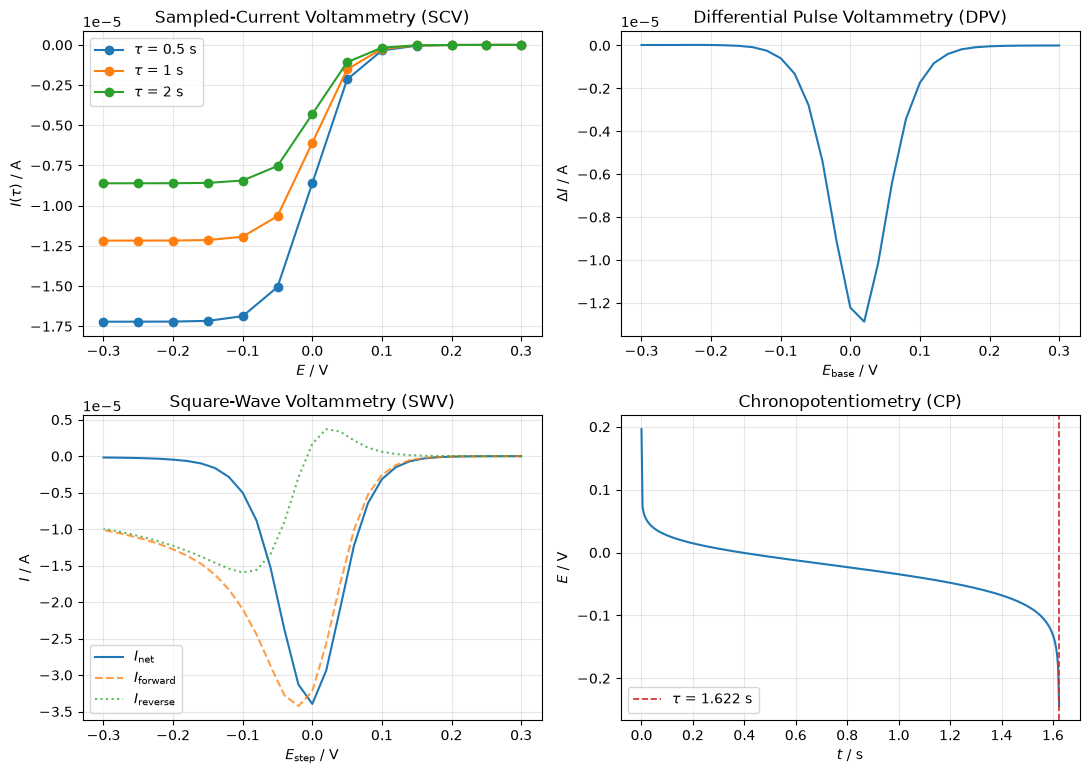

Simulated tau = 1.6216 s | Exact Sand tau = 1.6243 s
Extracted D   = 9.9834e-10 m^2/s (true: 1.0000e-09)


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
plot_scv(res_scv, ax=axes[0, 0])
axes[0, 0].set_title("Sampled-Current Voltammetry (SCV)")

plot_dpv(res_dpv, ax=axes[0, 1])
axes[0, 1].set_title("Differential Pulse Voltammetry (DPV)")

plot_swv(res_swv, ax=axes[1, 0])
axes[1, 0].set_title("Square-Wave Voltammetry (SWV)")

plot_result(res_cp, ax=axes[1, 1])
axes[1, 1].set_title("Chronopotentiometry (CP)")

plt.tight_layout()
plt.show()

sand_diag = analyze_sand(res_cp, n=1, area=area, c_bulk=c_bulk)
tau_exact = spa.sand_transition_time(I=-1.5e-5, n=1, D=D, c_bulk=c_bulk, area=area)
print(f"Simulated tau = {sand_diag.tau:.4f} s | Exact Sand tau = {tau_exact:.4f} s")
print(f"Extracted D   = {sand_diag.D_estimated:.4e} m^2/s (true: {D:.4e})")

## 5. Key Takeaways

- **SCV** produces sigmoidal steady-like waves at fixed sampling times $\tau$.
- **DPV** and **SWV** compute differential currents ($\Delta I$) that peak sharply near $E^{0\prime}$, offering superior sensitivity.
- **CP** holds constant current until surface concentration depletes at the **Sand transition time** $\tau$, where $E(t)$ drops sharply.
- **Next**: Read the [Pulse Voltammetry Guide](../../user-guide/techniques/pulse.md) or [Step Techniques Guide](../../user-guide/techniques/step.md).